In [1]:

import os
import matplotlib.pyplot as plt
import gc
import torch
import sys
sys.path.insert(0, os.path.abspath(os.path.join("..")))
from pipeline.preprocessing import BackgroundEraser
import glob

from PIL import Image
from torchvision import transforms

import pandas as pd
import re as regex_module
import numpy as np
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, fcluster

from ultralytics import YOLO

from pipeline.preprocessing import Repair, Normalizer, Augmentor
from pipeline.feature_learning.vae import VAE
from pipeline.feature_learning.vae_classifier import VAEClassifier
from pipeline.feature_learning.simclr import SimCLR
from pipeline.feature_learning.byol import BYOL
from pipeline.clustering import HierarchicalClustering
from pipeline.evaluation import EvaluationWithGroundTruth, EvaluationWithNoGroundTruth

In [4]:
print("CUDA_VISIBLE_DEVICES: ", os.environ["CUDA_VISIBLE_DEVICES"])
device = torch.device(0) # Will use the only visible GPU


CUDA_VISIBLE_DEVICES:  0


# PIPELINE

## Configuration

Set `source_folder` and `run_id` here, then any section below can be run
on its own (fresh kernel included) as long as this cell has run first -
every step reads/writes under `pipeline_dir`, which is namespaced by
`run_id`, so nothing else in the notebook needs editing when you point at
new photos or start a new experiment run.

- **New photos added to `source_folder`?** Just re-run from the top with
  a new `run_id` - the old run's outputs stay untouched under their own
  `pipeline_dir`.
- **Want to jump straight to e.g. Clustering?** Run this cell, then the
  cells in that section alone - they all read their input from disk via
  the paths defined here, not from variables set by earlier sections.

In [5]:
# --- Edit these two for a new run ------------------------------------
source_folder = "/caa/Homes01/alaczko/Diploma/Diploma/data/raw"
run_id = "run_2909___2"
# -----------------------------------------------------------------------

labels_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/ocr_data.csv"
test_image_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/pipeline/run_2909___2/augmented/00_Selection ML__2017_Survey und Ausgrabungen Gstettenbreite__GB_Surveyfunde_Scans_RZ_2017__DSt3__Unbenannt-21.jpg"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Every step's output lives under here, namespaced by run_id - switching
# run_id (or source_folder) is enough to start a fully separate run.
pipeline_dir = f"../data/pipeline/{run_id}"

erased_dir = f"{pipeline_dir}/PreprocessingStep/BackgroundEraser/"
normalized_dir = f"{pipeline_dir}/normalized" 
repaired_dir = f"{pipeline_dir}/repaired"
augmented_dir = f"{pipeline_dir}/augmented"

# Toggle: train VAE/VAEClassifier on the augmented set, or set this to
# repaired_dir to skip augmentation and train directly on the repaired images.
feature_learning_input_dir = repaired_dir

vae_checkpoint_path = f"{pipeline_dir}/vae.pt"
vae_features_csv = f"{pipeline_dir}/vae_features.csv"
simclr_checkpoint_path = f"{pipeline_dir}/simclr.pt"
simclr_features_csv = f"{pipeline_dir}/simclr_features.csv"
byol_checkpoint_path = f"{pipeline_dir}/byol.pt"
byol_features_csv = f"{pipeline_dir}/byol_features.csv"
dinov3_features_csv = f"{pipeline_dir}/dinov3_features.csv"
classifier_output_dir = f"{pipeline_dir}/classifier"

# Toggle: which feature set the Clustering section below clusters on.
features_csv_for_clustering = vae_features_csv
features_scaled_csv = f"{pipeline_dir}/features_scaled.csv"

roco_labels = pd.read_csv(labels_path)

## ocr data prep

In [44]:
import json
import pandas as pd

with open("../data/ocr_data.json", encoding="utf-8") as f:
    data = json.load(f)

df_ocr = pd.DataFrame([
    {"id": d["id"], "pottery_form": d.get("fields", {}).get("pottery_form")}
    for d in data
])


df_ocr = pd.json_normalize(data)[["id", "fields.pottery_form"]]
df_ocr.columns = ["id", "pottery_form"]
df_ocr[["location", "name"]] = df_ocr["id"].str.rsplit("/", n=1, expand=True)



In [45]:
prefixes = {
    "Excavation Gstettenbreite 1976 Sektor 5-6": "00_Selection ML__1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22__Sektor 5-6__",
    "Excavation Gstettenbreite 1976 Sektor 3-4": "00_Selection ML__1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22__Sektor 3-4__",
    "Excavation Gstettenbreite 1976 Sektor 1-2": "00_Selection ML__1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22__Sektor 1-2__",
    "Survey Gstettenbreite 2017": "00_Selection ML__2017_Survey und Ausgrabungen Gstettenbreite__GB_Surveyfunde_Scans_RZ_2017__",
    "Excavation Gstettenbreite 2017": "00_Selection ML__2017_Survey und Ausgrabungen Gstettenbreite__GB_EVN_Funde_Scans_RZ_2017__",
    "Excavation Petroneller Burg 2016": "00_Selection ML__2016_Petronell Kuenette und Limesgasse__LG_Funde_Scans_Künette_2016__",
    "Survey Käsemacherweide 2012": "00_Selection ML__2012_SurveyGladiatorenschule__",
    "Excavation Palastruine 1995": "00_Selection ML__1995_EVN-Künette Palastruine__",
}

mask = df_ocr["location"].isin(prefixes)
df_ocr.loc[mask, "id"] = df_ocr.loc[mask, "location"].map(prefixes) + df_ocr.loc[mask, "name"]


In [48]:
df_ocr["id"] = df_ocr["id"].str.rsplit(".", n=1).str[0]

In [50]:
df_ocr = df_ocr.rename(columns={"pottery_form": "TypeRev", "id": "ID"})


In [52]:
df_ocr.to_csv("../data/ocr_data.csv", index=False, encoding="utf-8")

## Preprocessing

### Shard selection and  background cleaning

In [ ]:
br = BackgroundEraser(
    input_path=source_folder,
    output_path=erased_dir,
    batch_size=128,
    num_workers=16,
    run_id=run_id,
)
#todo "detected 6171 shards, but erased len is 2800"
br.run()

Output path for step BackgroundEraser : ../data/pipeline/run_2909___2/PreprocessingStep/BackgroundEraser
Detecting shards...


Detecting shards: 100%|██████████| 6273/6273 [03:33<00:00, 29.31image/s]


Detected 6171 shard(s), failed on 102
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 1-2/064.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 11-12/004.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 19-20/068.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 19-20/367.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 2-3/218.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 2-3/245.jpg
  - /caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22/Sektor 2-3/370.jpg
  - 

Clearing images: 100%|██████████| 6171/6171 [17:57<00:00,  5.73it/s]


'../data/pipeline/run_2909___2/PreprocessingStep/BackgroundEraser'

### Resize & Crop

In [ ]:
crop_step = Normalizer(
    input_path=erased_dir,
    output_path=normalized_dir,
    background_color=(255, 255, 255),
    run_id=run_id,
)

crop_step.run()

Output path for step Normalizer : ../data/pipeline/run_2909___2/normalized


Normalizing images: 100%|██████████| 6171/6171 [15:39<00:00,  6.57image/s]  


PosixPath('../data/pipeline/run_2909___2/normalized')

### Enhancing Picture Quality

In [3]:
repair_step = Repair(
    input_path=normalized_dir,
    output_path=repaired_dir,
    contrast_factor=10.0,
    dilate_kernel_size=1,   
    dilate_iterations=1,
    skeletonize=False, 
    min_component_size=0,
    output_thickness=2,
)

repair_step.run()

Output path for step Repair : ../data/pipeline/run_2909___2/repaired


Repairing images: 100%|██████████| 6171/6171 [14:25<00:00,  7.13image/s]  


PosixPath('../data/pipeline/run_2909___2/repaired')

### Data Augmentation

Optional: grows the (small) labelled dataset with randomly rotated/flipped/
jittered copies before training, to fight the overfitting seen earlier when
fine-tuning `VAEClassifier` end to end. Sits right after `Repair`, before
any training step.

In [4]:
augment_step = Augmentor(
    input_path=repaired_dir,
    output_path=augmented_dir,
    num_augmentations=2,   # 2 extra randomly perturbed copies per image
    run_id=run_id,
)

augment_step.run()

Output path for step Augmentor : ../data/pipeline/run_2909___2/augmented


Augmenting images: 100%|██████████| 6171/6171 [21:53<00:00,  4.70image/s]  


PosixPath('../data/pipeline/run_2909___2/augmented')

Every Feature Learning cell below reads its input from
`feature_learning_input_dir` (set in Configuration) rather than a variable
from this section - it defaults to `augmented_dir`; set it to
`repaired_dir` there instead to skip augmentation.

## Feature Learning

### VAE

In [ ]:
vae = VAE(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)  # k=128 latent dimension
vae.to(device)

results = vae.run('train_model', epochs=500, lr=1e-4, batch_size=128)

torch.save(vae.state_dict(), vae_checkpoint_path)

Output path for step VAE : ../data/pipeline/run_2909___2/Module/VAE
Dataset size: 6171


In [6]:
vae = VAE(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)
vae.to(device)

vae.load_state_dict(torch.load(vae_checkpoint_path, map_location=device))

results = vae.extract_features(batch_size=128)

Output path for step VAE : ../data/pipeline/run_2909___2/Module/VAE


In [ ]:
results

,filename,features,sigma
0,00_Selection ML__1976_Schedivy Zivilstadt GB_S...,"[-1.4100621, -2.0148857, -3.9544106, -3.173621...","[-6.0911365, -5.2021074, -5.482678, -5.7064714..."
1,00_Selection ML__1976_Schedivy Zivilstadt GB_S...,"[-2.5920703, -2.8625925, -2.658386, -2.6651313...","[-4.9887447, -4.7703085, -4.8684793, -5.162761..."
2,00_Selection ML__1976_Schedivy Zivilstadt GB_S...,"[1.1733006, 1.2758415, -0.5078983, -3.261229, ...","[-5.6025743, -4.531424, -5.4479456, -5.11975, ..."
3,00_Selection ML__1976_Schedivy Zivilstadt GB_S...,"[-0.06516698, 2.8793223, -1.5189528, 1.1699436...","[-5.769492, -5.748885, -6.421737, -5.9273925, ..."
4,00_Selection ML__1976_Schedivy Zivilstadt GB_S...,"[-0.13089629, 2.5642643, 2.095658, -0.8311465,...","[-5.4214363, -6.2946105, -5.8938584, -5.437539..."
...,...,...,...
18508,00_Selection ML__2017_Survey und Ausgrabungen ...,"[-1.9331309, 3.0497112, 1.6475056, 0.06143236,...","[-6.2702336, -5.5088754, -5.7996254, -6.196516..."
18509,00_Selection ML__2017_Survey und Ausgrabungen ...,"[0.13654722, 3.4651191, -0.15418465, -1.805685...","[-5.8468385, -5.5362344, -5.5184402, -5.377155..."
18510,00_Selection ML__2017_Survey und Ausgrabungen ...,"[1.4871541, 1.9996339, 0.3198318, 2.875865, 0....","[-6.1474395, -5.4099402, -6.2096033, -5.846928..."
18511,00_Selection ML__2017_Survey und Ausgrabungen ...,"[-0.6156682, 0.6227559, 1.7816882, -2.6021194,...","[-6.2037816, -5.7646203, -6.001248, -5.241657,..."


In [8]:
results.to_csv(vae_features_csv, index=False)

#### Testing Feature Learning

Output path for step VAE : ../data/pipeline/run_2909___2/Module/VAE


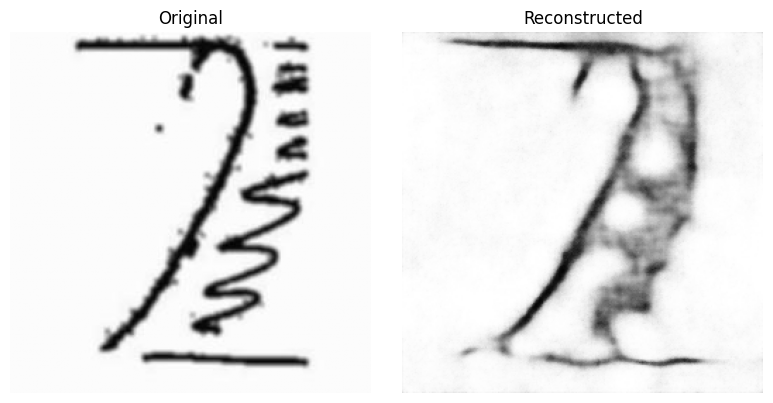

In [7]:
vae = VAE(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)
vae.to(device)

vae.load_state_dict(torch.load(vae_checkpoint_path, map_location=device))

#making sure the formula is correct
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

original_img = Image.open("/caa/Homes01/alaczko/Diploma/Diploma/data/pipeline/run_2909___2/augmented/00_Selection ML__2017_Survey und Ausgrabungen Gstettenbreite__GB_Surveyfunde_Scans_RZ_2017__DSt3__Unbenannt-10_aug1.jpg")
input_tensor = transform(original_img).unsqueeze(0).to(device) #adding batch dim

with torch.no_grad():
    reconstructed, mu, sigma = vae(input_tensor)

orig_np = input_tensor.squeeze().cpu().numpy()
recon_np = reconstructed.squeeze().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig_np, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(recon_np, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("Reconstructed")
axes[1].axis('off')

plt.tight_layout()
plt.show()

### SimCLR (contrastive feature learning, alternative to the VAE)

Trains the *same* `Encoder` architecture as the VAE (same `f`/`n`/`s`/`k`),
but with a contrastive objective instead of reconstruction: the encoder
learns to recognize that two differently-augmented views of the same
image belong together, and differ from every other image in the batch.
No labels needed.

Why try this alongside the VAE: since both use the identical backbone,
any difference in downstream clustering/classification accuracy between
the two isolates the *training objective* as the cause, not network
capacity - directly testing the hypothesis from the earlier discussion
that the VAE's reconstruction loss (not a lack of data) is what's
limiting its features' usefulness for classification.

In [ ]:
simclr = SimCLR(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)  # same architecture as the VAE
simclr.to(device)

simclr_results = simclr.run(
    "train_model",
    epochs=100,
    lr=1e-4,
    batch_size=128,
    temperature=0.5,
)

torch.save(simclr.state_dict(), simclr_checkpoint_path)

In [ ]:
simclr = SimCLR(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)
simclr.to(device)

simclr.load_state_dict(torch.load(simclr_checkpoint_path, map_location=device))

simclr_results = simclr.extract_features(batch_size=128)
simclr_results

In [ ]:
simclr_results.to_csv(simclr_features_csv, index=False)

To cluster on SimCLR features instead of the VAE's, set
`features_csv_for_clustering = simclr_features_csv` in Configuration
instead of `vae_features_csv`. Like DINOv3, SimCLR has no `sigma` (its
encoder is used deterministically here, no sampling) - so skip the
`df['sigma'] = ...` parsing line and the mu+sigma concatenation in the
scaling cell, and just standardize `df['features']` directly.

### BYOL (self-supervised, no negative pairs - alternative to SimCLR)

Like SimCLR, trains the same `SimCLREncoder` architecture to relate two
augmented views of the same image - but BYOL never contrasts against
*other* images at all, so there's no negative-pair pool and no
dependence on batch size for the loss to make sense (a real limitation
SimCLR has at this dataset's scale). Instead, BYOL keeps two copies of
the network: an "online" one trained normally, and a "target" one that's
only ever updated as an exponential moving average of the online
network's weights - the online network is trained to *predict* the
target network's view of the other augmented image.

Worth trying alongside SimCLR for the same reason SimCLR is worth trying
alongside the VAE: same backbone, different objective, so any difference
in downstream clustering quality isolates the objective as the cause.

In [ ]:
byol = BYOL(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)  # same encoder architecture as VAE/SimCLR
byol.to(device)

byol_results = byol.run(
    "train_model",
    epochs=100,
    lr=1e-4,
    batch_size=128,   # BYOL needs no negative-pair pool, so this can be smaller than SimCLR's
    early_stopping_patience=30
)

torch.save(byol.state_dict(), byol_checkpoint_path)

In [ ]:
byol = BYOL(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)
byol.to(device)

byol.load_state_dict(torch.load(byol_checkpoint_path, map_location=device))

byol_results = byol.extract_features(batch_size=128)
byol_results

In [ ]:
byol_results.to_csv(byol_features_csv, index=False)

To cluster on BYOL features instead, set
`features_csv_for_clustering = byol_features_csv` in Configuration. Like
SimCLR/DINOv3, BYOL has no `sigma` - skip the `df['sigma'] = ...` parsing
line and the mu+sigma concatenation in the scaling cell below, and just
standardize `df['features']` directly.

### DINOv3 (pretrained feature extractor, alternative to the VAE)

Instead of training an encoder from scratch, this uses Meta's DINOv3 - a
self-supervised Vision Transformer pretrained on ~1.7B natural images - as
a frozen feature extractor. No training happens here at all; every image
is just embedded once with the pretrained backbone.

Why try this: a VAE's encoder is only ever pushed to encode whatever makes
*pixel reconstruction* easy (see the earlier discussion on the encoder
being weak for classification) - DINO-style self-supervised training
optimizes for a much more discriminative objective, so its features tend
to transfer to downstream classification/clustering far better than plain
autoencoder features, even though DINOv3 was never shown an image of a
pottery sherd during its own training. It's a useful baseline for exactly
that reason: if DINOv3's *generic* features already separate your pottery
types better than the *purpose-built* VAE does, that's strong evidence the
VAE (or its BCE+KL training objective) - not the amount of data - is the
bottleneck.

**Before running this**: DINOv3 checkpoints are gated on Hugging Face.
Accept the license at the model page (e.g.
https://huggingface.co/facebook/dinov3-vitb16-pretrain-lvd1689m) with the
account you'll authenticate with, then run `huggingface-cli login` once
(or set the `HF_TOKEN` environment variable) before executing the next
cell - otherwise the download will fail with a 403.

In [ ]:
from transformers import AutoImageProcessor, AutoModel

# Swap for "facebook/dinov3-vits16-pretrain-lvd1689m" (smaller/faster) or
# "facebook/dinov3-vitl16-pretrain-lvd1689m" (larger/slower, likely better
# features) to compare backbone sizes.
DINOV3_MODEL_NAME = "facebook/dinov3-vitb16-pretrain-lvd1689m"

dinov3_processor = AutoImageProcessor.from_pretrained(DINOV3_MODEL_NAME)
dinov3_model = AutoModel.from_pretrained(DINOV3_MODEL_NAME).to(device)
dinov3_model.eval()  # frozen - inference only, no training/fine-tuning here

In [ ]:
from pipeline.preprocessing.dataset import collect_image_paths


@torch.no_grad()
def extract_dinov3_features(image_paths, batch_size=32):
    """Embed each image with the frozen DINOv3 backbone's CLS token - the
    standard whole-image descriptor for ViT-style models, analogous to the
    VAE's `mu`. Returns a 'filename' + 'features' row per image, i.e. the
    same shape as `VAE.extract_features`'s output, so it can be pointed at
    directly from the Clustering section below by just swapping the CSV
    path - no other changes needed there.
    """
    filenames = []
    all_features = []

    for start in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[start:start + batch_size]
        # DINOv3 (like most ImageNet-pretrained ViTs) expects 3-channel
        # RGB input; convert("RGB") turns our grayscale line drawings into
        # a 3-channel image with all channels equal.
        images = [Image.open(p).convert("RGB") for p in batch_paths]

        inputs = dinov3_processor(images=images, return_tensors="pt").to(device)
        outputs = dinov3_model(**inputs)
        cls_embeddings = outputs.last_hidden_state[:, 0, :]

        filenames.extend(p.name for p in batch_paths)
        all_features.append(cls_embeddings.cpu())

    features = torch.cat(all_features, dim=0).numpy()
    return pd.DataFrame({"filename": filenames, "features": list(features)})


dinov3_image_paths = collect_image_paths(feature_learning_input_dir)
print(f"Found {len(dinov3_image_paths)} images for DINOv3 feature extraction")

dinov3_results = extract_dinov3_features(dinov3_image_paths, batch_size=128)
dinov3_results

In [ ]:
dinov3_results.to_csv(dinov3_features_csv, index=False)

To cluster on DINOv3 features instead of the VAE's, set
`features_csv_for_clustering = dinov3_features_csv` in Configuration
instead of `vae_features_csv`. One difference to account for: DINOv3 has
no `sigma` (it's deterministic, not a VAE) - so skip the
`df['sigma'] = ...` parsing line and the mu+sigma concatenation in the
scaling cell, and just standardize `df['features']` directly (single
`mu_matrix`-equivalent, no `hstack`).

### Classifier

In [ ]:
vae = VAE(input_path=feature_learning_input_dir, f=4, n=3, s=1, k=128, run_id=run_id)
vae.to(device)

vae.load_state_dict(torch.load(vae_checkpoint_path, map_location=device))

In [ ]:
classifier = VAEClassifier(
    input_path=feature_learning_input_dir,
    vae=vae,                         # a fentebb betanított VAE
    num_classes=28,
    labels_path=labels_path,
    freeze_encoder=True,             # először csak a classifier tanul
    output_path=classifier_output_dir,
    run_id=run_id,
).to(device)

history = classifier.run(
    epochs=200,
    lr=1e-4,
    batch_size=128,
    validation_size=0.2,
    num_workers=16,
)

history

## Clustering

In [53]:
df = pd.read_csv(features_csv_for_clustering)

In [54]:
import numpy as np
import ast

def parse_feature_string(s):
    if isinstance(s, str):
        cleaned = s.strip('[]')
        # tetszőleges mennyiségű whitespace -> egyetlen szóköz
        cleaned = regex_module.sub(r'\s+', ' ', cleaned).strip()
        return np.fromstring(cleaned, sep=' ')
    return np.asarray(s)

In [55]:
df['features'] = df['features'].apply(parse_feature_string)

In [56]:
X = np.vstack(df['features'].values)

# 2. inaktív / szinte nulla varianciájú dimenziók kiszűrése (opcionális, de ajánlott)
variances = X.var(axis=0)
active_dims = variances > 1e-3   # threshold-öt finomítsd a saját adatodra
X_active = X[:, active_dims]

# 3. standardizálás (dimenziónkénti z-score)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_active)

df["features_non_scaled"] = df['features'] 

# 4. opcionálisan visszaírhatod a df-be, hogy egyben tudd kezelni
df['features'] = list(X_scaled)

df.to_csv(features_scaled_csv, index=False)

In [57]:
df.head()

,filename,features,sigma,features_non_scaled
0,00_Selection ML__1976_Schedivy Zivilstadt GB_Sektoren 1-2 bis 21-22__Sektor 1-2__001.jpg,"[-0.6669782086992084, -1.1664055055446685, -2.118743452732386, -1.4943625217498337, -1.986461945371108, 3.76115806295506, -0.9602959980835027, -0.18294008040372475, -0.9241716875490257, 0.32450169921262184, 3.613123276275873, -1.2596533998565531, 1.805453428593009, -0.04900593711417287, 0.3272171592533466, 2.5038208529977792, -0.8465365598187533, -0.7150447652534305, -0.9361438375186729, -0.8488248504571709, -0.9982799365114751, 1.0167315403700128, 0.06609847100119187, 3.0488578748927795, 1.6316939659513598, 0.91190468730467, -0.28224135513861054, 0.5387250469512357, 0.5456333360038275, -2.9976268139910913, 0.02060469405164803, -0.3618030882466865, 3.7813374013834458, 1.5586352656585225, -1.012820983104475, 0.8399819473437223, 1.01340299238204, -1.5756937507718514, -0.43620001553279036, -1.1040957118351413, 0.998658986516781, 0.4072629634352556, 2.5041955884161697, -1.644691566243716, 1.8709943688420063, 0.6420614818957725, 1.724987398348504, 0.5478044323081452, -0.0165404588231886, -1.6008709116593112, 0.8129586561099725, 0.23630450409899112, -0.6795979137138476, -0.19823221975249297, -1.3038884523820518, -1.4382544038922702, -0.3709469246650649, -0.37656318468361893, 0.8896802369947656, -0.6743676633016016, -0.13192913278792173, 0.8484428153159337, 0.6426442336103505, 0.2064027584531752, -0.5018078299553672, -1.093907476601749, -0.5216511175355358, -0.7541536658265413, 1.4814217064017108, 0.1666506396937491, 1.6499985017838155, -1.5702825623020482, -1.0354503430698367, 0.9596619241463659, 0.03551473002164332, 0.2785357513519355, 0.6174183776097337, 0.8417588551475156, -0.8176619062126075, -0.17830507986307342, -1.787655789551749, 0.4076166215923121, 0.5028258892688707, -0.3779549752649985, -0.777070993749452, 0.28997711625822165, 1.292906524544344, -0.4006727667005361, -1.8576113839825228, -3.459102037141247, 0.7376841424856866, -1.6430951604712292, -0.6921413054667283, 0.5518253282324856, -1.2351430900862062, -0.03421870597493367, 0.10126894544001926, -1.7815027301283275, 0.7160597835875021, -0.40324382829349237, ...]",[ -6.0911 -5.2021 -5.4827 -5.7065 -6.0005 -5.6098 -5.6661 -6.1146 -5.7925 -5.9434 -5.6198 -5.2742 -6.1829 -6.0632 -5.5694 -5.7035 -5.3804 -5.548 -5.5667 -5.618 -5.5772 -5.8903 -6.5925 -5.5141 -5.827 -5.5435\n -5.7741 -5.8572 -6.3351 -4.8947 -5.4109 -5.3122 -5.4593 -6.1711 -5.9565 -5.6662 -5.5806 -5.41 -5.6026 -5.8411 -5.8563 -5.7574 -5.8662 -5.8376 -4.4444 -6.5554 -5.7522 -5.6937 -5.2625 -5.1152 -5.5727 -4.9\n -6.0777 -5.947 -5.4985 -5.8876 -6.2116 -5.8615 -6.3491 -5.5847 -5.9621 -5.2087 -5.5133 -5.9109 -4.7697 -5.527 -5.3387 -4.8007 -6.339 -5.7965 -5.4878 -5.3897 -5.251 -5.1006 -6.1814 -6.1479 -5.7167 -5.4511\n -5.6836 -5.9782 -5.9841 -5.455 -5.2302 -5.47 -5.7339 -5.8052 -6.2479 -4.7586 -5.4447 -5.4553 -5.6814 -5.4558 -5.9692 -5.778 -5.534 -5.4267 -5.7816 -5.2894 -5.9348 -6.0518 -5.7857 -5.4879 -4.6069 -6.6423\n -5.4132 -5.4152 -5.5981 -5.6869 -5.6297 -5.5882 -5.3069 -5.9005 -5.0786 -6.4522 -5.6765 -6.9328 -4.9127 -6.4017 -5.2881 -5.8222 -6.2567 -5.2773 -6.0589 -5.1201 -5.7712 -5.5075 -5.6839 -5.7509],"[-1.4101, -2.0149, -3.9544, -3.1736, -2.7041, 6.6454, -1.46, -0.86853, -1.6344, 0.83739, 6.267, -2.3236, 2.6778, 0.034337, 0.49224, 4.3847, -1.5745, -1.3036, -1.4331, -1.2296, -2.2885, 1.6271, 0.91314, 5.3034, 2.6453, 1.2811, -0.10577, 1.602, 0.60602, -5.2052, -0.7199, -0.21164, 6.5969, 2.7972, -1.2371, 1.4347, 1.4426, -2.3809, -0.73618, -2.238, 1.4858, 0.46099, 4.3388, -2.6483, 4.1573, 0.75133, 3.6577, 1.0172, 0.36663, -2.4336, 1.0592, 0.27712, -1.4658, -0.26169, -1.8718, -1.8945, -0.3912, -0.56908, 1.2606, -1.2471, -0.20194, 1.2033, 0.61555, 0.74539, -0.57298, -1.8938, -0.88541, -2.0082, 2.3219, -0.11095, 2.5291, -2.6841, -1.8979, 1.5693, 0.058902, 0.30309, 1.2513, 2.3041, -2.0782, -0.83082, -2.8234, 0.85595, 0.71754, -0.59387, -2.1077, 0.74789, 2.4202, -0.64375, -3.3697, -

In [58]:
clustering_step = HierarchicalClustering(
    input_path=features_scaled_csv,
    cluster_num=5,
    run_id=run_id,
)
# result= clustering_step.run()


#result = clustering_step.compare_all()

Output path for step HierarchicalClustering : ../data/pipeline/run_2909___2/ClusteringStep/HierarchicalClustering


In [59]:
result= clustering_step.run()

In [ ]:
import shutil
from pathlib import Path
clusters_output_dir = Path(pipeline_dir) / "clusters"
source_dir = Path(feature_learning_input_dir)
def resolve_image_path(filename):
    candidate = source_dir / filename
    if candidate.exists():
        return candidate
    # Robust to df["filename"] already having had its extension stripped
    # (see the base_id cell further down) - fall back to matching by stem.
    matches = list(source_dir.glob(f"{Path(filename).stem}.*"))
    return matches[0] if matches else None
saved, missing = 0, 0
for filename, cluster_id in zip(df["filename"], result):
    src_path = resolve_image_path(filename)
    if src_path is None:
        missing += 1
        continue
    cluster_dir = clusters_output_dir / f"cluster_{cluster_id}"
    cluster_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src_path, cluster_dir / src_path.name)
    saved += 1
print(f"Saved {saved} images into {clusters_output_dir} ({len(set(result))} clusters), {missing} missing.")

Saved 0 images into ../data/pipeline/run_legion_bb/clusters (28 clusters), 4620 missing.


In [29]:
np.unique(result, return_counts=True)

(array([1, 2, 3, 4, 5], dtype=int32),
 array([    9,     2,     2, 18499,     1]))

#### Silhouette Score (no ground truth needed)

In [60]:
# Unsupervised evaluation: uses only the feature vectors + predicted cluster
# labels, so it works even before/without matching against ground-truth types.
silhouette_step = EvaluationWithNoGroundTruth(features=clustering_step.vectors, y_pred=result)
silhouette_step.run()

Predicted labels: [4 4 4 ... 4 4 4]
Calculating silhouette score...
-----
Evaluation results: 
Silhouette Score = 0.32136521517111427
-----




In [61]:
df["pred"] = list(result)

In [62]:
df["filename"] = df["filename"].str.rsplit(".", n=1).str[0]

# Augmentor saves augmented copies as "<original>_aug0", "<original>_aug1",
# etc., which have no matching row in roco_labels (only the original ID
# does). base_id strips that suffix back off, so every augmented copy is
# looked up under its source image's label - correct, since augmentation
# doesn't change what type the sherd actually is.
df["base_id"] = df["filename"].str.replace(r"_aug\d+$", "", regex=True)

In [77]:
new_df = pd.merge(
    df,
    roco_labels,
    left_on="base_id",
    right_on="ID",
    how="inner"
)

In [83]:
new_df = new_df.dropna(subset=["pred", "TypeRev"]).reset_index(drop=True)

In [84]:
new_df.isna().sum()

filename               0
features               0
sigma                  0
features_non_scaled    0
pred                   0
base_id                0
ID                     0
TypeRev                0
location               0
name                   0
dtype: int64

In [72]:
pd.set_option("display.max_colwidth", 150)


In [85]:
eval_step = EvaluationWithGroundTruth(y_true=new_df["TypeRev"].values, y_pred=new_df["pred"].values)

Ground truth labels: ['Becher' 'Becher' 'Becher' ... 'Teller' 'Teller' 'Teller']
Predicted labels: [4 4 4 ... 4 4 4]


In [86]:
eval_step.run()

-----
Evaluation results: 
ACC = 0.24347826086956523, 
ARI = 0.0, 
NMI = 0.0
-----




In [ ]:
features_path = features_scaled_csv

cluster_numbers = range(3, 60)
metric_results = []

# A features.csv sorrendjében találhatók a klaszterezés bemenetei
features_df = pd.read_csv(features_path)

features_df["filename"] = (
    features_df["filename"]
    .astype(str)
    .str.strip()
    .str.rsplit(".", n=1)
    .str[0]
)

# See the base_id comment above: augmented copies ("<original>_aug0", ...)
# need this suffix stripped to find their source image's label.
features_df["base_id"] = features_df["filename"].str.replace(r"_aug\d+$", "", regex=True)

In [ ]:
for cluster_num in cluster_numbers:
    clustering_step = HierarchicalClustering(
        input_path=features_path,
        cluster_num=cluster_num,
        run_id=run_id,
    )

    predicted_labels = clustering_step.run()

    # Unsupervised metric: doesn't need the ground-truth join below, so it's
    # computed on every sample that went into clustering.
    silhouette_step = EvaluationWithNoGroundTruth(
        features=clustering_step.vectors, y_pred=predicted_labels
    )
    silhouette_step.run()

    predictions_df = features_df[["filename", "base_id"]].copy()
    predictions_df["pred"] = predicted_labels

    # Az új klasztercímkék hozzárendelése a meglévő dataframe-hez
    current_df = pd.merge(
        predictions_df,
        roco_labels,
        left_on="base_id",
        right_on="ID",
        how="inner"
    )

    current_df = current_df.dropna(subset=["pred", "TypeRev"]).reset_index(drop=True)

    y_true = current_df["TypeRev"].to_numpy()
    y_pred = current_df["pred"].to_numpy()


    eval_step = EvaluationWithGroundTruth(y_true=y_true, y_pred=y_pred)

    eval_step.run()

    metric_results.append({
        "cluster_num": cluster_num,
        "ACC": eval_step.acc,
        "ARI": eval_step.ari,
        "NMI": eval_step.nmi,
        "Silhouette": silhouette_step.silhouette,
        "sample_count": len(current_df),
        "predicted_cluster_count": current_df["pred"].nunique(),
    })

metrics_df = pd.DataFrame(metric_results)
metrics_df

Output path for step HierarchicalClustering : ../data/pipeline/run_legion_bb/ClusteringStep/HierarchicalClustering
Predicted labels: [1 1 1 ... 1 1 1]
Calculating silhouette score...
-----
Evaluation results: 
Silhouette Score = 0.23738429988119117
-----


Ground truth labels: ['pan' 'pan' 'pan' ... 'lid' 'lid' 'dish-lid']
Predicted labels: [1 1 1 ... 1 1 1]
-----
Evaluation results: 
ACC = 0.24428975418751359, 
ARI = 0.00021149960807236994, 
NMI = 0.0016330177379210399
-----


Output path for step HierarchicalClustering : ../data/pipeline/run_legion_bb/ClusteringStep/HierarchicalClustering
Predicted labels: [1 1 1 ... 1 1 1]
Calculating silhouette score...
-----
Evaluation results: 
Silhouette Score = 0.2019361329789675
-----


Ground truth labels: ['pan' 'pan' 'pan' ... 'lid' 'lid' 'dish-lid']
Predicted labels: [1 1 1 ... 1 1 1]
-----
Evaluation results: 
ACC = 0.2445072873613226, 
ARI = 0.0003202934807794878, 
NMI = 0.0022875675652411953
-----


Output path for step HierarchicalClus

,cluster_num,ACC,ARI,NMI,Silhouette,sample_count,predicted_cluster_count
0,3,0.244290,0.000211,0.001633,0.237384,4597,3
1,4,0.244507,0.000320,0.002288,0.201936,4597,4
2,5,0.244725,0.000397,0.002812,0.161684,4597,5
3,6,0.246465,0.001892,0.008697,0.147191,4597,6
4,7,0.246248,0.001891,0.008869,0.144585,4597,7
5,8,0.246683,0.002354,0.010602,0.128211,4597,8
6,9,0.247118,0.002355,0.012084,0.114675,4597,9
7,10,0.246900,0.002431,0.013166,0.096181,4597,10
8,11,0.247118,0.002806,0.014479,0.080363,4597,11
9,12,0.246900,0.002757,0.014917,0.068313,4597,12


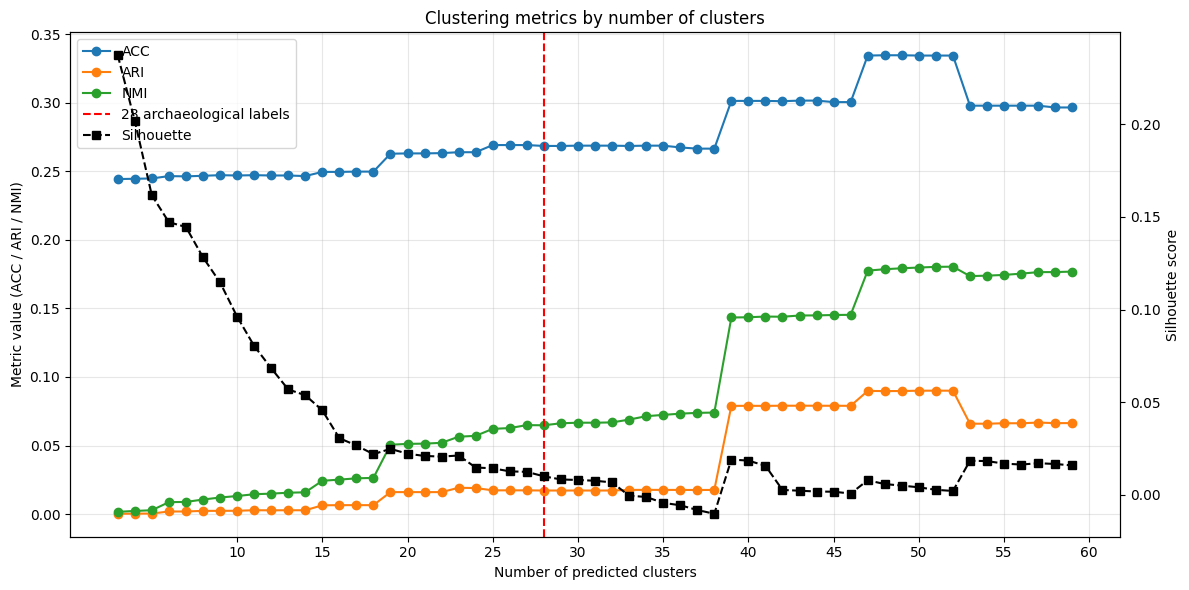

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    metrics_df["cluster_num"],
    metrics_df["ACC"],
    marker="o",
    label="ACC"
)

ax1.plot(
    metrics_df["cluster_num"],
    metrics_df["ARI"],
    marker="o",
    label="ARI"
)

ax1.plot(
    metrics_df["cluster_num"],
    metrics_df["NMI"],
    marker="o",
    label="NMI"
)

ax1.axvline(
    28,
    color="red",
    linestyle="--",
    label="28 archaeological labels"
)

ax1.set_xlabel("Number of predicted clusters")
ax1.set_ylabel("Metric value (ACC / ARI / NMI)")
ax1.set_xticks(range(10, 61, 5))
ax1.grid(alpha=0.3)

# Silhouette score has a different range ([-1, 1], unsupervised - no ground
# truth involved) than ACC/ARI/NMI, so it gets its own y-axis rather than
# being squashed onto the same 0-1 scale.
ax2 = ax1.twinx()
ax2.plot(
    metrics_df["cluster_num"],
    metrics_df["Silhouette"],
    marker="s",
    color="black",
    linestyle="--",
    label="Silhouette",
)
ax2.set_ylabel("Silhouette score")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("Clustering metrics by number of clusters")
plt.tight_layout()
plt.show()

In [ ]:
new_df

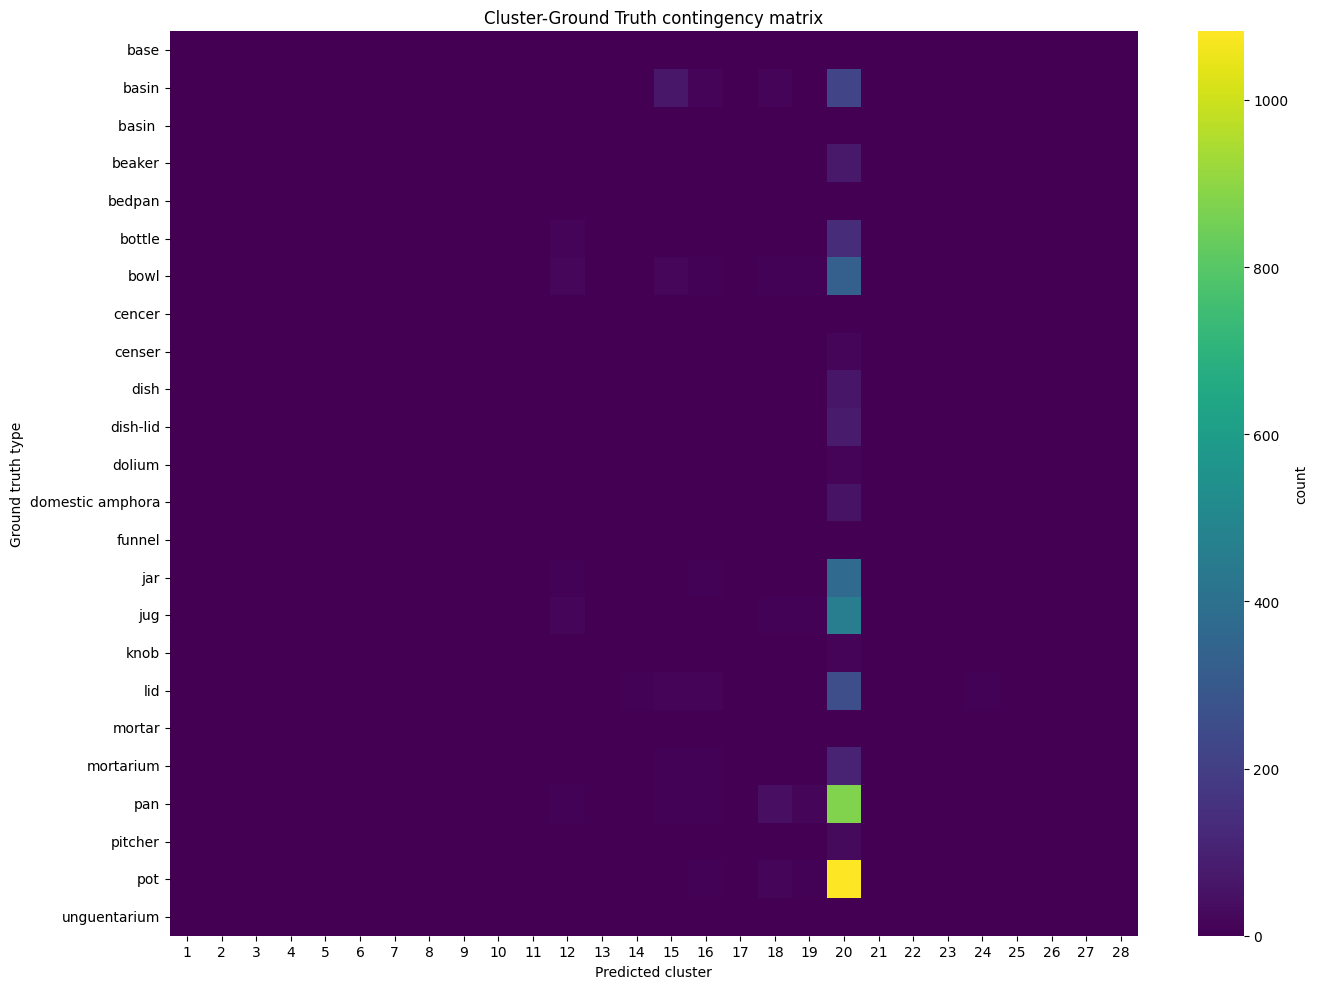

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# df-ben legyen egy 'pred' (predikált cluster) és egy 'true_label' (ground truth) oszlop
contingency = pd.crosstab(new_df['TypeRev'], new_df['pred'])

plt.figure(figsize=(14, 10))
sns.heatmap(contingency, annot=False, cmap='viridis', cbar_kws={'label': 'count'})
plt.xlabel('Predicted cluster')
plt.ylabel('Ground truth type')
plt.title('Cluster-Ground Truth contingency matrix')
plt.tight_layout()
plt.show()